# CEDAR — Suspicious Activities Detection in Public Procurement

Risk scores for every node of the procurement graph, computed as **similarity to the two anomaly scenarios of the methodology**:

1. **Potential collusion between organizations** — extracted through 3-organization → 1-tender motifs, expanded to maximum cliques, then analyzed (success rate, fake competition, winner rotation, responsible-person consistency).
2. **Potential repeated favoritism** — extracted through quadruplet motifs (public entity + 3-organization group where one of them wins), then analyzed (success rate, targeting rate, official consistency, restricted competition).

**Principles kept simple:**
- Every tender has **at least 3 bids**, so every organization is extractable through a 3-organization motif — the motif is the universal starting point.
- Repetition scale: **1 co-occurrence = normal · 2 = attention · 3 = suspicious** (the ≥3 extraction threshold). Similarity is **convex** — `sim(x,t) = min(x/t, 1)²` — because being a third of the way to a pattern is much less than a third of the risk: normal nodes land near 0.01–0.1, the middle spreads, only exact scenario matches reach 1.
- **The success criterion gates everything**, in the methodology's own order (Step 3 flags on success, Step 4's checks describe the flagged group): `gate = min(sr/0.75, 1) × sim(wins, 3)` — attainment at *maturity*, since a rate over one or two wins is not evidence. Then `success = gate × sr` (75 % → 0.75, only total capture → 1) and every further check counts `× gate`.
- **Score = repetition × strongest check** of the group.
- **Involvement rule** — after clique detection, *everyone inside the clique's tenders* is scored through the clique, gaining its full anomaly context: `involvement(k) = min((contacts+1)/4, 1)²` → one contact 0.25, two 0.56, three or more = full member. Core members and absorbed members (Org_16) get the whole clique's evidence; a single-bid newcomer inside a cartel tender is visibly lifted without being condemned.
- **Groups that have not achieved an anomaly stay in a proximity band ≤ 0.55**; achieving the criterion *augments* the score into the achieved band (0.75–1.0). This protects selection from over-reacting to close-but-not-there groups while reacting immediately once the suspicious activity is done.
- **Storage pipeline**: the generated market is persisted to a **local Neo4j** graph following the **CEDAR data model** (PublicEntity —ISSUES→ Tender ←SUBMITTED_FOR— Bid ←SUBMITS— Organization, with the model's attribute names), then read back and loaded into a **Raphtory temporal graph** where the analysis runs.
- All values are fixed by the scenario definitions — nothing is calibrated on the generated data.

In [1]:
import random
from datetime import datetime, timedelta
from collections import defaultdict
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from raphtory import Graph   # pip install raphtory

sns.set(style="whitegrid", palette="deep")
random.seed(42); np.random.seed(42)

## 1 — Scenario thresholds (fixed, explained)

| Threshold | Value | Where it comes from |
|---|---|---|
| `REPEAT` | 3 | the extraction rule: the same group co-appearing ≥ 3 times indicates potential coordination. Convex scale: 1 → 0.11, 2 → 0.44, 3 → 1.0 |
| `SUCCESS` | 75 % | the cartel criterion. Combined with maturity into the **gate** = `min(sr/0.75, 1) × sim(wins, 3)`; success score = `gate × sr`, further checks `× gate` |
| `BID_GAP` | 25 % | fake competition: losing bids on average > 25 % above the winner |
| `WINS_MIN` | 3 | a success rate, rotation pattern or official/person share over fewer than 3 wins is not yet evidence |
| `PROXIMITY_CAP` | 0.55 | **two regimes**: below the success criterion, the gate lives in a proximity band `0.55 × (sr/0.75)²` — so a group *approaching* the anomaly never exceeds ~0.55 and cannot distort selection; the moment the criterion is achieved the gate augments to full and the score jumps into the achieved band (0.75–1.0) |

Derived, with their rationale: `sim(x,t) = min(x/t, 1)²` (convex similarity — partial proximity is much less than partial risk, keeping normal and *new* participants near 0.01–0.1); `involvement(k) = min((k+1)/4, 1)²` (presence inside an established group counts with a +1 head start because the pattern already exists: 1 contact → 0.25, 2 → 0.56, 3 → member). These are statements about the *scenarios*, never calibrated on this dataset.

In [2]:
THRESHOLDS = {
    "REPEAT": 3,        # slide: motif recurring >= 3 => suspicious group
    "SUCCESS": 0.75,    # slide: success rate > 75% => potential cartel
    "BID_GAP": 0.25,    # slide: avg gap winner vs others > 25% => fake competition
    "WINS_MIN": 3,      # rotation needs a minimal number of wins to mean anything
    "PROXIMITY_CAP": 0.55,  # groups NOT achieving the success criterion stay in
                            # a proximity band <= 0.55; achieving it AUGMENTS the
                            # score into the achieved band (0.75-1.0)
}


def sim(x, target):
    """Convex similarity to a scenario criterion: min(x/target, 1) squared.
    Being a third of the way to a pattern is much less than a third of the
    risk — this keeps normal nodes ~0.1 and spreads the middle."""
    return float(min(max(x, 0) / target, 1.0) ** 2)


def involvement(k):
    """Presence inside an ESTABLISHED group's tenders. The pattern already
    exists, so a first appearance counts with a +1 head start:
    1 contact -> 0.25, 2 -> 0.56, 3+ -> full member (1.0)."""
    return float(min((k + 1) / (THRESHOLDS["REPEAT"] + 1), 1.0) ** 2)


## 2 — Synthetic market with planted scenarios

Every tender has ≥ 3 bidders. Besides the honest background, the market contains organizations of *every* involvement level so the score gradient is visible:

| Scenario | Nodes | Behaviour | Expected score |
|---|---|---|---|
| Background (35 tenders) | Org_0–19 | honest competition | ≲ 0.05 |
| **Ring** (×5+) | Org_1, Org_5, Org_9 | rotating winner, cover bids +25–45 %, fixed signers | 1.0 (exact scenario) |
| **3-occurrence ring** (×3) | Org_3, Org_5, Org_7 | dominant winner, mild padding | ~1.0 (the ≥3 rule, fully successful) |
| **Favoritism** (×5) | Entity_0 → Org_2/6/11, Org_16 in 3 | same official, same signers, normal prices | entity 1.0; **expansion absorbs Org_16 with full clique context** |
| **Near-cartel** (×4) | Org_10, Org_12, Org_14 | wins 3 of 4 (75 % — criterion just achieved), mild padding | 0.75 — the augmentation point |
| **One-shot group** (×1) | Org_32/33/34 | a single tender, padded bids, tight submissions | ~0.01 — one appearance is no pattern, however suspicious it looks |
| **Repeating losers** (×4) | Org_28/29/30 | co-bid 4×, win once, mild padding | ~0.01 — repetition without success does not select |
| **Halfway group** (×5) | Org_35/36/37 | wins 3 of 5 (60 % < 75 %), heavy padding, fixed signers | ~0.35 — proximity band, capped below 0.55 |
| **Coincidence** (×2) | Org_13/14/15 | competitive | in-between, well under 0.6 |
| **Small participants** | Org_20–23 (1–2 bids), Entity_6 (2 tenders) | honest | ≲ 0.05 |
| **New joiners** | Org_25/26/27 with 3/2/1 bids; Entity_7 with one tender | honest | ≲ 0.05 — new players get a score, a low one |
| **Single cartel contact** | Org_24 — one bid, inside a ring tender | honest price | ~0.25 via involvement |
| Peripheral | Org_18 — two bids inside ring tenders | — | ~0.56 via involvement |

In [3]:
ORGS = [f"Org_{i}" for i in range(20)]            # regular market
SMALL_ORGS = [f"Org_{i}" for i in range(20, 24)]  # 1-2 bids only
CONTACT_ORG = "Org_24"                            # bids once, inside a cartel tender
ENTITIES = [f"Entity_{i}" for i in range(6)]
SMALL_ENTITY = "Entity_6"                         # publishes only 2 tenders
ORG_PERSONS = [f"Person_{i:02d}" for i in range(50)]  # 50-69 assigned to ladder orgs below
OFFICIALS = [f"Official_{i}" for i in range(10)]

pool = ORG_PERSONS.copy()
random.shuffle(pool)
responsible_people = {org: [pool.pop(), pool.pop()]
                      for org in ORGS + SMALL_ORGS + [CONTACT_ORG]}
entity_officials = {e: random.sample(OFFICIALS, 2) for e in ENTITIES + [SMALL_ENTITY]}

rows = []
tender_seq = 0
BASE = datetime(2025, 1, 1, 8, 0)


def add_tender(entity, participants, winner, base_price, day,
               spread_minutes, price_fn, people_fn, official=None):
    global tender_seq
    tid = f"T{tender_seq}"
    tender_seq += 1
    t0 = BASE + timedelta(days=day, minutes=random.randint(0, 300))
    off = official or random.choice(entity_officials[entity])
    for org in participants:
        rows.append({
            "TenderID": tid,
            "PublicEntity": entity,
            "EntityOfficial": off,
            "Organization": org,
            "BidAmount": round(price_fn(org, winner, base_price), 2),
            "SubmissionTime": t0 + timedelta(minutes=random.uniform(0, spread_minutes)),
            "ResponsiblePerson": people_fn(org),
            "Winner": winner,
        })
    return tid


# --- background: honest competition, persons rotate ---
for k in range(35):
    entity = random.choice(ENTITIES)
    participants = random.sample(ORGS, random.randint(3, 6))
    winner = random.choice(participants)
    base_price = random.randint(100_000, 300_000)

    def price(org, win, bp):
        return bp * (random.uniform(0.96, 1.02) if org == win
                     else random.uniform(0.98, 1.15))

    add_tender(entity, participants, winner, base_price,
               day=random.randint(0, 180), spread_minutes=48 * 60,
               price_fn=price,
               people_fn=lambda o: random.choice(responsible_people[o]))

# --- scenario A: full ring, SAME persons every time ---
RING_A = ("Org_1", "Org_5", "Org_9")
FAV_GROUP = ("Org_2", "Org_6", "Org_11")   # defined early: scenario pools stay disjoint
ring_a_people = {o: responsible_people[o][0] for o in RING_A}
for i in range(5):
    entity = random.choice(ENTITIES[:3])
    participants = list(RING_A)
    if i < 2:
        participants.append("Org_18")   # touches the cartel twice
    elif i == 2:
        participants.append(CONTACT_ORG)  # single bid, inside a cartel tender
    winner = RING_A[i % 3]
    base_price = random.randint(150_000, 300_000)

    def price(org, win, bp):
        if org == win:
            return bp * random.uniform(0.95, 0.99)
        if org in RING_A:
            return bp * random.uniform(1.25, 1.45)
        return bp * random.uniform(0.99, 1.10)

    add_tender(entity, participants, winner, base_price,
               day=random.randint(0, 180), spread_minutes=8,
               price_fn=price,
               people_fn=lambda o: ring_a_people.get(o, random.choice(responsible_people[o])))

# --- scenario B: partial ring, persons rotate (org-level pattern only) ---
RING_B = ("Org_3", "Org_5", "Org_7")
for i in range(3):
    entity = random.choice(ENTITIES)
    winner = "Org_3" if random.random() < 0.7 else random.choice(RING_B)
    base_price = random.randint(120_000, 250_000)

    def price(org, win, bp):
        if org == win:
            return bp * random.uniform(0.96, 1.0)
        if org in RING_B:
            return bp * random.uniform(1.12, 1.28)
        return bp * random.uniform(0.98, 1.10)

    add_tender(entity, list(RING_B), winner, base_price,
               day=random.randint(0, 180), spread_minutes=45,
               price_fn=price,
               people_fn=lambda o: random.choice(responsible_people[o]))

# --- scenario C: favoritism, SAME official + SAME org persons ---
fav_people = {o: responsible_people[o][0] for o in FAV_GROUP}
FAV_OFFICIAL = entity_officials["Entity_0"][0]
for i in range(5):
    # Org_16 co-appears WITHOUT completing the core triplet: the case
    # only motif-based clique expansion can absorb
    participants = list(FAV_GROUP)
    if i < 3:
        participants.append("Org_16")
    others = [o for o in ORGS if o not in FAV_GROUP and o not in RING_A
              and o not in ("Org_16", "Org_18")]
    participants += random.sample(others, 1)
    winner = "Org_2" if random.random() < 0.75 else random.choice(FAV_GROUP)
    base_price = random.randint(180_000, 350_000)

    def price(org, win, bp):
        return bp * (random.uniform(0.95, 0.99) if org == win
                     else random.uniform(1.0, 1.12))

    add_tender("Entity_0", participants, winner, base_price,
               day=random.randint(0, 180), spread_minutes=24 * 60,
               price_fn=price,
               people_fn=lambda o: fav_people.get(o, random.choice(responsible_people[o])),
               official=FAV_OFFICIAL)

# --- scenario D: coincidental repeats, persons rotate ---
COINC = ("Org_13", "Org_14", "Org_15")
for i in range(2):
    entity = random.choice(ENTITIES)
    pool = [o for o in ORGS if o not in COINC and o not in RING_A
            and o not in FAV_GROUP
            and o not in ("Org_16", "Org_18")]
    participants = list(COINC) + random.sample(pool, 2)
    winner = random.choice(participants)
    base_price = random.randint(100_000, 250_000)

    def price(org, win, bp):
        return bp * (random.uniform(0.96, 1.01) if org == win
                     else random.uniform(0.99, 1.12))

    add_tender(entity, participants, winner, base_price,
               day=random.randint(0, 180), spread_minutes=72 * 60,
               price_fn=price,
               people_fn=lambda o: random.choice(responsible_people[o]))

# --- scenario F: near-cartel — repeats 4x but only partly matches ---
NEAR_GROUP = ("Org_10", "Org_12", "Org_14")
for i in range(4):
    participants = list(NEAR_GROUP)
    if i % 2:
        participants.append(random.choice(
            [o for o in ORGS if o not in NEAR_GROUP and o not in RING_A
             and o not in FAV_GROUP]))
    winner = (NEAR_GROUP[0], NEAR_GROUP[0], NEAR_GROUP[1])[i] if i < 3 \
        else random.choice([o for o in participants if o not in NEAR_GROUP]
                           or [participants[0]])
    base_price = random.randint(120_000, 250_000)

    def price(org, win, bp):
        if org == win:
            return bp * random.uniform(0.96, 1.0)
        if org in NEAR_GROUP:
            return bp * random.uniform(1.10, 1.18)   # mild padding only
        return bp * random.uniform(0.99, 1.08)

    add_tender(random.choice(ENTITIES), participants, winner, base_price,
               day=random.randint(0, 180), spread_minutes=6 * 60,
               price_fn=price,
               people_fn=lambda o: random.choice(responsible_people[o]))

# --- new joiners: organizations with exactly 1, 2 and 3 honest bids ---
NEW_ORGS = ["Org_25", "Org_26", "Org_27"]        # 3, 2, 1 bids respectively
for org, n_bids in zip(NEW_ORGS, (3, 2, 1)):
    responsible_people[org] = [f"Person_{45 + NEW_ORGS.index(org)}"]
    for _ in range(n_bids):
        participants = [org] + random.sample(
            [o for o in ORGS if o not in RING_A and o not in FAV_GROUP], 3)
        winner = random.choice(participants)
        base_price = random.randint(100_000, 220_000)

        def price(o_, win, bp):
            return bp * (random.uniform(0.96, 1.01) if o_ == win
                         else random.uniform(0.99, 1.10))

        add_tender(random.choice(ENTITIES), participants, winner, base_price,
                   day=random.randint(0, 180), spread_minutes=72 * 60,
                   price_fn=price,
                   people_fn=lambda o_: random.choice(responsible_people[o_]))

# --- new public entity with a single tender ---
NEW_ENTITY = "Entity_7"
entity_officials[NEW_ENTITY] = random.sample(OFFICIALS, 1)
participants = random.sample([o for o in ORGS if o not in RING_A
                              and o not in FAV_GROUP], 4)
winner = random.choice(participants)
bp0 = random.randint(150_000, 300_000)
add_tender(NEW_ENTITY, participants, winner, bp0,
           day=random.randint(0, 180), spread_minutes=72 * 60,
           price_fn=lambda o, w, bp: bp * (random.uniform(0.96, 1.01) if o == w
                                           else random.uniform(0.99, 1.10)),
           people_fn=lambda o: random.choice(responsible_people[o]))

# --- degradation ladder: groups at different distances from the scenarios ---
# L1: a triplet that appears exactly ONCE, suspicious-looking in that tender
G_ONCE = ("Org_32", "Org_33", "Org_34")
# L2: repeats 4x but keeps LOSING to outsiders — repetition without success
G_LOSE = ("Org_28", "Org_29", "Org_30")
# L3: halfway — repeats 5x, wins 3 of 5 (60% < 75%), heavy padding, fixed people
G_HALF = ("Org_35", "Org_36", "Org_37")
for i, org in enumerate(G_ONCE + G_LOSE + G_HALF):
    responsible_people[org] = [f"Person_{50 + 2 * i}", f"Person_{51 + 2 * i}"]

winner = G_ONCE[0]
add_tender(random.choice(ENTITIES), list(G_ONCE), winner,
           random.randint(150_000, 250_000),
           day=random.randint(0, 180), spread_minutes=15,
           price_fn=lambda o, w, bp: bp * (random.uniform(0.95, 0.99) if o == w
                                           else random.uniform(1.28, 1.38)),
           people_fn=lambda o: responsible_people[o][0])

for i in range(4):
    outsiders = random.sample([o for o in ORGS if o not in RING_A
                               and o not in FAV_GROUP], 2)
    participants = list(G_LOSE) + outsiders
    winner = outsiders[0] if i < 3 else G_LOSE[0]
    add_tender(random.choice(ENTITIES), participants, winner,
               random.randint(100_000, 220_000),
               day=random.randint(0, 180), spread_minutes=24 * 60,
               price_fn=lambda o, w, bp: bp * (random.uniform(0.96, 1.0) if o == w
                                               else random.uniform(1.08, 1.15)),
               people_fn=lambda o: random.choice(responsible_people[o]))

for i in range(5):
    participants = list(G_HALF)
    if i >= 3:
        participants.append(random.choice(
            [o for o in ORGS if o not in RING_A and o not in FAV_GROUP]))
    winner = G_HALF[i % 3] if i < 3 else participants[-1]
    add_tender(random.choice(ENTITIES), participants, winner,
               random.randint(120_000, 240_000),
               day=random.randint(0, 180), spread_minutes=90,
               price_fn=lambda o, w, bp: bp * (random.uniform(0.95, 0.99) if o == w
                                               else (random.uniform(1.26, 1.34)
                                                     if o in G_HALF
                                                     else random.uniform(0.99, 1.08))),
               people_fn=lambda o: responsible_people[o][0] if o in G_HALF
               else random.choice(responsible_people[o]))

# --- small participants: organizations with only 1-2 bids ---
for i in range(3):
    smalls = [SMALL_ORGS[(2 * i) % 4], SMALL_ORGS[(2 * i + 1) % 4]]
    regs = random.sample([o for o in ORGS if o not in RING_A
                          and o not in FAV_GROUP], 2)
    participants = smalls + regs
    winner = random.choice(participants)
    base_price = random.randint(100_000, 250_000)

    def price(org, win, bp):
        return bp * (random.uniform(0.96, 1.01) if org == win
                     else random.uniform(0.99, 1.12))

    add_tender(random.choice(ENTITIES), participants, winner, base_price,
               day=random.randint(0, 180), spread_minutes=72 * 60,
               price_fn=price,
               people_fn=lambda o: random.choice(responsible_people[o]))

# --- small entity: publishes only 2 honest tenders ---
for i in range(2):
    participants = random.sample([o for o in ORGS if o not in RING_A
                                  and o not in FAV_GROUP], 4)
    winner = random.choice(participants)
    base_price = random.randint(100_000, 250_000)

    def price(org, win, bp):
        return bp * (random.uniform(0.96, 1.01) if org == win
                     else random.uniform(0.99, 1.12))

    add_tender(SMALL_ENTITY, participants, winner, base_price,
               day=random.randint(0, 180), spread_minutes=72 * 60,
               price_fn=price,
               people_fn=lambda o: random.choice(responsible_people[o]))

df = pd.DataFrame(rows)
df["BidID"] = df["TenderID"] + "_" + df["Organization"]

print("tenders:", df.TenderID.nunique(), "| orgs:", df.Organization.nunique(),
      "| bids:", len(df), "| min bidders per tender:",
      df.groupby("TenderID").Organization.nunique().min())

tenders: 76 | orgs: 37 | bids: 310 | min bidders per tender: 3


## 3 — Persist to Neo4j following the CEDAR data model

The market is stored in a **local Neo4j** instance using the data model's entities, relations and attribute names (the entities `Item` and `ResponsiblePerson` and the attributes not used by these scenarios are omitted):

| Label | Attributes used | Relations |
|---|---|---|
| `PublicEntity` | `id_public_entity` | `(:PublicEntity)-[:ISSUES]->(:Tender)` |
| `Tender` | `id_tender`, `winning_bid`, `awarded_price`, `responsible_signee_name` (the entity-side official), `time_publication` | `(:Bid)-[:SUBMITTED_FOR]->(:Tender)` |
| `Bid` | `id_bid`, `time_submission`, `contract_price`, `responsible_signee_name` (the org-side signer), `successful_bid` | `(:Organization)-[:SUBMITS]->(:Bid)` |
| `Organization` | `id_organization` | — |

Note how the model carries the two person types exactly as before, as attributes on opposite sides: `Bid.responsible_signee_name` signs for the organization, `Tender.responsible_signee_name` manages for the public entity; and `Tender.winning_bid` + `Bid.successful_bid` identify the winning bid.

Run a local Neo4j (e.g. Neo4j Desktop / `docker run neo4j`) and adjust `NEO4J_URI` / `NEO4J_AUTH`. If no instance is reachable, the notebook falls back to building the temporal graph directly from the staging rows — **the row shape is identical to the Cypher read-back**, so every downstream cell is the same either way.

In [4]:
NEO4J_URI = "bolt://localhost:7687"
NEO4J_AUTH = ("neo4j", "password")          # adjust to your local instance


def staging_to_rows(df):
    """One row per bid with the DATA MODEL attribute names — the same shape
    the Cypher read-back returns, so the temporal graph builder is identical
    with or without Neo4j."""
    rows = []
    for tid, sub in df.groupby("TenderID"):
        winner = sub.Winner.iloc[0]
        wrow = sub.loc[sub.Organization == winner].iloc[0]
        for _, b in sub.iterrows():
            rows.append({
                "id_tender": tid,
                "time_publication": sub.SubmissionTime.min(),
                "winning_bid": wrow.BidID,
                "awarded_price": float(wrow.BidAmount),
                "tender_signee": b.EntityOfficial,       # Tender.responsible_signee_name
                "id_public_entity": b.PublicEntity,
                "id_organization": b.Organization,
                "id_bid": b.BidID,
                "time_submission": b.SubmissionTime,
                "contract_price": float(b.BidAmount),
                "bid_signee": b.ResponsiblePerson,       # Bid.responsible_signee_name
                "successful_bid": bool(b.Organization == winner),
            })
    return rows


def load_to_neo4j(rows, uri=NEO4J_URI, auth=NEO4J_AUTH):
    """Persist the market as a CEDAR-data-model graph in a local Neo4j:
    (:PublicEntity)-[:ISSUES]->(:Tender)<-[:SUBMITTED_FOR]-(:Bid)<-[:SUBMITS]-(:Organization)"""
    from neo4j import GraphDatabase
    drv = GraphDatabase.driver(uri, auth=auth)
    with drv.session() as s:
        s.run("MATCH (n) DETACH DELETE n")
        s.run("""
            UNWIND $rows AS r
            MERGE (pe:PublicEntity {id_public_entity: r.id_public_entity})
            MERGE (t:Tender {id_tender: r.id_tender})
              SET t.winning_bid = r.winning_bid,
                  t.awarded_price = r.awarded_price,
                  t.responsible_signee_name = r.tender_signee,
                  t.time_publication = r.time_publication
            MERGE (pe)-[:ISSUES]->(t)
            MERGE (o:Organization {id_organization: r.id_organization})
            MERGE (b:Bid {id_bid: r.id_bid})
              SET b.time_submission = r.time_submission,
                  b.contract_price = r.contract_price,
                  b.responsible_signee_name = r.bid_signee,
                  b.successful_bid = r.successful_bid
            MERGE (o)-[:SUBMITS]->(b)
            MERGE (b)-[:SUBMITTED_FOR]->(t)
        """, rows=[{**r,
                    "time_publication": r["time_publication"].isoformat(),
                    "time_submission": r["time_submission"].isoformat()}
                   for r in rows])
    drv.close()


def read_from_neo4j(uri=NEO4J_URI, auth=NEO4J_AUTH):
    from neo4j import GraphDatabase
    import pandas as _pd
    drv = GraphDatabase.driver(uri, auth=auth)
    with drv.session() as s:
        res = s.run("""
            MATCH (pe:PublicEntity)-[:ISSUES]->(t:Tender)
                  <-[:SUBMITTED_FOR]-(b:Bid)<-[:SUBMITS]-(o:Organization)
            RETURN t.id_tender AS id_tender,
                   t.time_publication AS time_publication,
                   t.winning_bid AS winning_bid,
                   t.awarded_price AS awarded_price,
                   t.responsible_signee_name AS tender_signee,
                   pe.id_public_entity AS id_public_entity,
                   o.id_organization AS id_organization,
                   b.id_bid AS id_bid,
                   b.time_submission AS time_submission,
                   b.contract_price AS contract_price,
                   b.responsible_signee_name AS bid_signee,
                   b.successful_bid AS successful_bid
        """)
        rows = [dict(r) for r in res]
    drv.close()
    for r in rows:
        r["time_publication"] = _pd.Timestamp(r["time_publication"])
        r["time_submission"] = _pd.Timestamp(r["time_submission"])
    return rows


def build_temporal_graph(rows):
    """Raphtory temporal graph with the data model's names:
    node types PublicEntity / Tender / Bid / Organization,
    layers ISSUES / SUBMITS / SUBMITTED_FOR, bid time = time_submission."""
    from raphtory import Graph
    g = Graph()
    for r in rows:
        g.add_node(r["time_publication"], r["id_tender"],
                   properties={"winning_bid": r["winning_bid"],
                               "awarded_price": r["awarded_price"],
                               "responsible_signee_name": r["tender_signee"]},
                   node_type="Tender")
        g.add_node(r["time_publication"], r["id_public_entity"],
                   node_type="PublicEntity")
        g.add_edge(r["time_publication"], r["id_public_entity"],
                   r["id_tender"], layer="ISSUES")
        g.add_node(r["time_submission"], r["id_organization"],
                   node_type="Organization")
        g.add_node(r["time_submission"], r["id_bid"],
                   properties={"contract_price": r["contract_price"],
                               "responsible_signee_name": r["bid_signee"],
                               "successful_bid": r["successful_bid"]},
                   node_type="Bid")
        g.add_edge(r["time_submission"], r["id_organization"], r["id_bid"],
                   layer="SUBMITS")
        g.add_edge(r["time_submission"], r["id_bid"], r["id_tender"],
                   layer="SUBMITTED_FOR")
    return g

rows = staging_to_rows(df)
try:
    load_to_neo4j(rows)
    rows = read_from_neo4j()
    print(f"Neo4j round-trip OK: {len(rows)} bid rows read back via Cypher")
except Exception as exc:
    print("Neo4j not reachable -> falling back to staging rows "
          f"(same shape as the Cypher read-back). [{type(exc).__name__}]")
print("rows:", len(rows), "| sample:", {k: rows[0][k] for k in
      ("id_tender", "id_organization", "id_bid", "contract_price",
       "successful_bid")})

Neo4j round-trip OK: 310 bid rows read back via Cypher
rows: 310 | sample: {'id_tender': 'T46', 'id_organization': 'Org_2', 'id_bid': 'T46_Org_2', 'contract_price': 216835.06, 'successful_bid': True}


## 4 — Neo4j → Raphtory temporal graph

The rows become a **temporal graph**: same structure, same names, plus time — bid nodes live at their `time_submission`, tenders at `time_publication`, which is what enables windowed analysis later. `tender_index` then traverses `SUBMITTED_FOR` and `SUBMITS` edges and reads the model's properties; the winner is the organization whose bid has `successful_bid = true`. The analysis reads only this traversal output.

In [5]:
g = build_temporal_graph(rows)
print("temporal graph:", g.count_nodes(), "nodes |", g.count_edges(),
      "edges | types:", g.get_all_node_types())

def tender_index(g):
    """One pass over the temporal graph, following the data model's relations;
    the analysis reads only this."""
    idx = {}
    for t in g.nodes.type_filter(["Tender"]):
        recs, winner = [], None
        for e in t.in_edges:
            if "SUBMITTED_FOR" not in e.layer_names:
                continue
            b = e.src
            org = [ie.src.name for ie in b.in_edges
                   if "SUBMITS" in ie.layer_names][0]
            recs.append({"bid": b.name, "org": org,
                         "amount": b.properties.get("contract_price"),
                         "person": b.properties.get("responsible_signee_name")})
            if b.properties.get("successful_bid"):
                winner = org
        entity = [e.src.name for e in t.in_edges if "ISSUES" in e.layer_names][0]
        idx[t.name] = {"entity": entity,
                       "official": t.properties.get("responsible_signee_name"),
                       "winner": winner,
                       "winner_bid": t.properties.get("awarded_price"),
                       "bids": recs,
                       "participants": sorted({r["org"] for r in recs})}
    return idx

T = tender_index(g)
print("tenders indexed:", len(T))

temporal graph: 431 nodes | 696 edges | types: ['Tender', 'PublicEntity', 'Organization', 'Bid']
tenders indexed: 76


In [7]:
for node in g.nodes:
    break

In [10]:
node.node_type


'Tender'

## 4 — Collusion, Step 1: extract suspicious groups through motif counting

3-organization → 1-tender motifs are counted over the whole graph. Groups recurring **≥ 3 times** are extracted as suspicious; the bar chart reads exactly like the methodology slide — blue = normal (1), orange = attention (2), red = suspicious (≥ 3).

suspicious groups (>= 3):
  ('Org_1', 'Org_5', 'Org_9'): 6
  ('Org_11', 'Org_2', 'Org_6'): 5
  ('Org_35', 'Org_36', 'Org_37'): 5
  ('Org_10', 'Org_12', 'Org_14'): 4
  ('Org_28', 'Org_29', 'Org_30'): 4
  ('Org_3', 'Org_5', 'Org_7'): 3
  ('Org_11', 'Org_16', 'Org_2'): 3
  ('Org_11', 'Org_16', 'Org_6'): 3
  ('Org_16', 'Org_2', 'Org_6'): 3
  ('Org_13', 'Org_17', 'Org_3'): 3


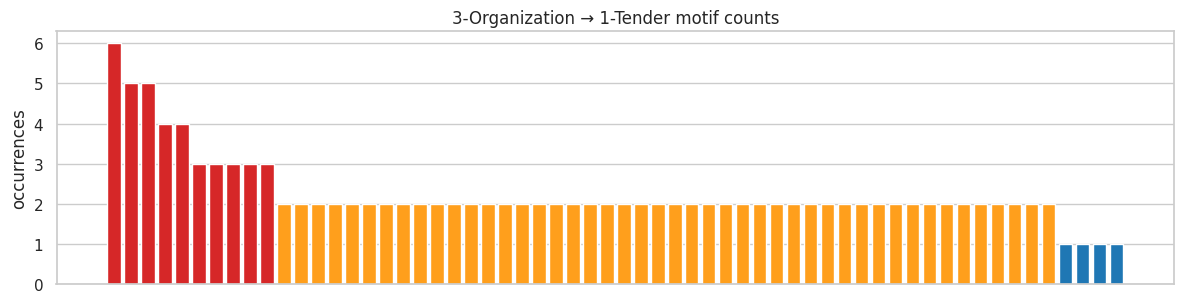

In [12]:
def org_motifs(T):
    """3-organization -> 1-tender motifs (org+bid merged by traversal)."""
    trip = defaultdict(int)
    for t in T.values():
        for tr in combinations(t["participants"], 3):
            trip[tr] += 1
    return trip


def suspicious_groups(trip):
    return {tr: c for tr, c in trip.items() if c >= THRESHOLDS["REPEAT"]}

trip = org_motifs(T)
groups = suspicious_groups(trip)
print("suspicious groups (>= 3):")
for tr, c in sorted(groups.items(), key=lambda x: -x[1]):
    print(f"  {tr}: {c}")

counts = sorted(trip.values(), reverse=True)[:60]
colors = ["#d62728" if c >= 3 else "#ff9f1c" if c == 2 else "#1f77b4"
          for c in counts]
plt.figure(figsize=(12, 3.2))
plt.bar(range(len(counts)), counts, color=colors)
plt.title("3-Organization → 1-Tender motif counts")
plt.ylabel("occurrences"); plt.xticks([])
plt.tight_layout(); plt.show()

## 5 — Collusion, Step 2: maximum cliques through motif-based expansion

Suspicious motifs are building blocks; motifs sharing 2 organizations (central actors) merge into the **maximum clique** — the check for a cartel *bigger than any single motif*. In this market the favoritism motifs merge into a 4-organization clique: Org_16 never completes the core triplet yet belongs to the coordinated structure.

In [13]:
def max_cliques(groups):
    """Motif-based expansion: merge motifs sharing 2 orgs (central actors)."""
    keys = list(groups)
    parent = {i: i for i in range(len(keys))}

    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    for i, j in combinations(range(len(keys)), 2):
        if len(set(keys[i]) & set(keys[j])) >= 2:
            parent[find(i)] = find(j)

    merged = defaultdict(list)
    for i in range(len(keys)):
        merged[find(i)].append(keys[i])

    cliques = []
    for motifs in merged.values():
        orgs = sorted(set().union(*motifs))
        cliques.append({
            "orgs": orgs, "motifs": motifs,
            "participation": {o: sum(groups[m] for m in motifs if o in m)
                              for o in orgs}})
    return cliques

cliques = max_cliques(groups)
for c in cliques:
    central = sorted(c["participation"].items(), key=lambda x: -x[1])
    bigger = " <- BIGGER than a single motif" if len(c["orgs"]) > 3 else ""
    print(f"CLIQUE {c['orgs']}  central actors: {central[:2]}{bigger}")

CLIQUE ['Org_3', 'Org_5', 'Org_7']  central actors: [('Org_3', 3), ('Org_5', 3)]
CLIQUE ['Org_1', 'Org_5', 'Org_9']  central actors: [('Org_1', 6), ('Org_5', 6)]
CLIQUE ['Org_10', 'Org_12', 'Org_14']  central actors: [('Org_10', 4), ('Org_12', 4)]
CLIQUE ['Org_11', 'Org_16', 'Org_2', 'Org_6']  central actors: [('Org_11', 11), ('Org_2', 11)] <- BIGGER than a single motif
CLIQUE ['Org_35', 'Org_36', 'Org_37']  central actors: [('Org_35', 5), ('Org_36', 5)]
CLIQUE ['Org_28', 'Org_29', 'Org_30']  central actors: [('Org_28', 4), ('Org_29', 4)]
CLIQUE ['Org_13', 'Org_17', 'Org_3']  central actors: [('Org_13', 3), ('Org_17', 3)]


## 6 — Collusion, Steps 3–4: checks and organization scores

For every extracted group (clique or triplet) the methodology's checks run over the group's joint tenders, each as a similarity:

- **success_rate** — wins by any member / appearances, vs 75 %
- **fake_competition** — average % gap of members' losing bids above the winner, vs 25 %
- **winner_rotation** — evenness of the win distribution (entropy / log |G|), maturing only after ≥ 3 wins
- **person_consistency** — share of one same responsible person signing a member's bids, × repetition

**Score of an organization.** Established groups (cliques and ≥3 motifs) are scored once: `repetition × strongest gated check`. Then **every organization appearing in the group's tenders — core member, absorbed member, or single contact — receives the group's score × its involvement**, so clique members are judged with the full context of the clique's anomalies, and a one-bid newcomer inside a cartel tender is lifted to ~0.25 rather than condemned. Organizations touching no established group are scored through their own most frequent triplet, which the maturity gate keeps near 0.01–0.05.

In [14]:
def group_checks(G, T):
    """The presentation's checks for one group, each as scenario similarity."""
    G = set(G)
    tenders = [t for t in T.values()
               if len(G & set(t["participants"])) >= min(3, len(G))]
    n = len(tenders)
    out = {"appearances": n, "repetition": sim(n, THRESHOLDS["REPEAT"])}
    if n == 0:
        out.update({"success_rate": 0, "fake_competition": 0,
                    "winner_rotation": 0, "person_consistency": 0})
        return out

    wins = [t["winner"] for t in tenders if t["winner"] in G]
    sr = len(wins) / n
    # the methodology flags on success first; the further checks describe the
    # flagged group, so everything counts in proportion to the success gate.
    # TWO REGIMES: below the criterion the gate lives in a proximity band
    # capped at PROXIMITY_CAP; achieving the criterion augments it to full.
    # Maturity applies in both (a rate over 1-2 wins is not yet evidence).
    attain = (1.0 if sr >= THRESHOLDS["SUCCESS"]
              else THRESHOLDS["PROXIMITY_CAP"] * (sr / THRESHOLDS["SUCCESS"]) ** 2)
    gate = attain * sim(len(wins), THRESHOLDS["WINS_MIN"])
    out["success_rate"] = gate * sr

    gaps = [(r["amount"] - t["winner_bid"]) / t["winner_bid"]
            for t in tenders for r in t["bids"]
            if r["org"] in G and r["org"] != t["winner"] and t["winner_bid"]]
    out["fake_competition"] = sim(np.mean(gaps) if gaps else 0,
                                  THRESHOLDS["BID_GAP"]) * gate

    if wins:
        p = pd.Series(wins).value_counts(normalize=True)
        evenness = -(p * np.log(p)).sum() / np.log(len(G))
        out["winner_rotation"] = abs(evenness) * gate
    else:
        out["winner_rotation"] = 0.0

    # most frequent signer of one member's bids (a share, capped by nature)
    top_share = 0.0
    for o in G:
        ppl = [r["person"] for t in tenders for r in t["bids"] if r["org"] == o]
        if ppl:
            top_share = max(top_share,
                            pd.Series(ppl).value_counts(normalize=True).iloc[0])
    out["person_consistency"] = top_share * gate
    return out

ORG_CHECKS = ["repetition", "success_rate", "fake_competition",
              "winner_rotation", "person_consistency"]

def org_scores(T, trip, cliques):
    """Established groups (cliques and >=3 motifs) are scored once; every
    organization appearing in their tenders — core member or single contact —
    receives the group's score scaled by its involvement, so clique members
    get the full context of the clique's anomalies. Everyone else is scored
    through their own most frequent triplet (low, graded proximity)."""
    established = [tuple(cl["orgs"]) for cl in cliques] + \
        [tr for tr in suspicious_groups(trip)
         if not any(set(tr) <= set(cl["orgs"]) for cl in cliques)]

    est = {}
    for G in established:
        ch = group_checks(G, T)
        checks = {k: ch[k] for k in ORG_CHECKS[1:]}
        est[G] = {"checks": checks, "repetition": ch["repetition"],
                  "overall": ch["repetition"] * max(checks.values()),
                  "tenders": [t for t in T.values()
                              if len(set(G) & set(t["participants"]))
                              >= min(3, len(G))]}

    top_trip = {}
    for tr, c in trip.items():
        for o in tr:
            if c > top_trip.get(o, ((), 0))[1]:
                top_trip[o] = (tr, c)

    rows = {}
    for o in sorted({o for t in T.values() for o in t["participants"]}):
        # path 1: involvement in an established group
        best = {"overall": -1}
        for G, e in est.items():
            k = sum(1 for t in e["tenders"] if o in t["participants"])
            if k == 0:
                continue
            inv = involvement(k)
            cand = {**e["checks"], "repetition": e["repetition"],
                    "involvement": inv, "overall": e["overall"] * inv,
                    "group": G}
            if cand["overall"] > best["overall"]:
                best = cand
        # path 2: fallback — the org's own top triplet
        tr = top_trip.get(o, ((), 0))[0]
        if tr:
            ch = group_checks(tr, T)
            checks = {k: ch[k] for k in ORG_CHECKS[1:]}
            cand = {**checks, "repetition": ch["repetition"],
                    "involvement": 1.0,
                    "overall": ch["repetition"] * max(checks.values()),
                    "group": tr}
            if cand["overall"] > best["overall"]:
                best = cand
        if best["overall"] < 0:
            best = {**{k: 0.0 for k in ORG_CHECKS[1:]}, "repetition": 0.0,
                    "involvement": 0.0, "overall": 0.0, "group": None}
        rows[o] = best
    A = pd.DataFrame(rows).T
    A["nearest_scenario"] = A[ORG_CHECKS[1:]].astype(float).idxmax(axis=1)
    return A

org_A = org_scores(T, trip, cliques)
org_A.sort_values("overall", ascending=False).round(3)

,success_rate,fake_competition,winner_rotation,person_consistency,repetition,involvement,overall,group,nearest_scenario
Org_9,0.833333,1.0,0.96023,1.0,1.0,1.0,1.0,"(Org_1, Org_5, Org_9)",fake_competition
Org_16,1.0,0.092385,0.0,1.0,1.0,1.0,1.0,"(Org_11, Org_16, Org_2, Org_6)",success_rate
Org_2,1.0,0.092385,0.0,1.0,1.0,1.0,1.0,"(Org_11, Org_16, Org_2, Org_6)",success_rate
Org_5,1.0,0.86548,0.0,1.0,1.0,1.0,1.0,"(Org_3, Org_5, Org_7)",success_rate
Org_1,0.833333,1.0,0.96023,1.0,1.0,1.0,1.0,"(Org_1, Org_5, Org_9)",fake_competition
Org_6,1.0,0.092385,0.0,1.0,1.0,1.0,1.0,"(Org_11, Org_16, Org_2, Org_6)",success_rate
Org_7,1.0,0.86548,0.0,1.0,1.0,1.0,1.0,"(Org_3, Org_5, Org_7)",success_rate
Org_11,1.0,0.092385,0.0,1.0,1.0,1.0,1.0,"(Org_11, Org_16, Org_2, Org_6)",success_rate
Org_3,1.0,0.86548,0.0,1.0,1.0,1.0,1.0,"(Org_3, Org_5, Org_7)",success_rate
Org_14,0.75,0.457726,0.57938,0.5,1.0,1.0,0.75,"(Org_10, Org_12, Org_14)",success_rate


## 7 — Favoritism: entity ↔ organization-group quadruplet motifs

Quadruplet motifs — one public entity + a 3-organization group participating in its tender **with one of them winning** — are counted; ≥ 3 recurrences extract a suspicious entity ↔ group pair. The checks, each as similarity:

- **success_rate** of the group in that entity's tenders, vs 75 %
- **targeting_rate** — the group's tenders at this entity / the group's tenders everywhere (a group repeatedly aiming at one entity expects something there)
- **official_consistency** — share of the group's won tenders managed by the same official, maturing after ≥ 3 wins
- **restricted_competition** — |group| / distinct organizations seen in those tenders (an inner circle leaves few outsiders)

Entity score = `repetition × strongest check` of its most anomalous group.

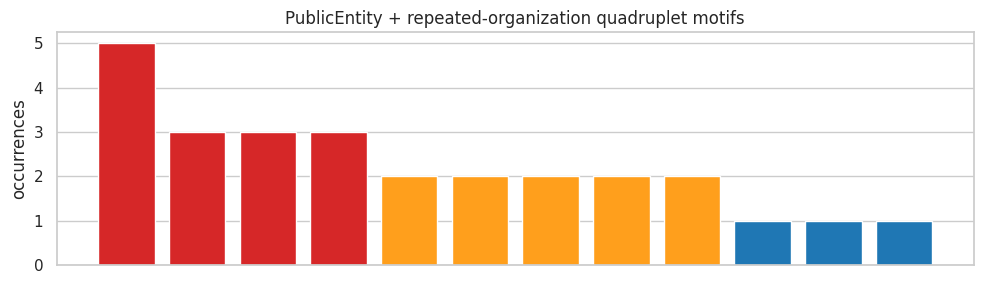

,success_rate,targeting_rate,official_consistency,restricted_competition,repetition,overall,group,nearest_scenario
Entity_0,1.0,1.0,1.0,0.140625,1.0,1.0,"(Org_11, Org_2, Org_6)",success_rate
Entity_1,0.197531,0.197531,0.098765,0.197531,0.444444,0.197531,"(Org_10, Org_12, Org_8)",success_rate
Entity_4,0.197531,0.197531,0.197531,0.071111,0.444444,0.197531,"(Org_13, Org_16, Org_18)",success_rate
Entity_2,0.012346,0.012346,0.012346,0.004444,0.111111,0.012346,"(Org_0, Org_10, Org_28)",success_rate
Entity_3,0.012346,0.012346,0.012346,0.006944,0.111111,0.012346,"(Org_10, Org_12, Org_13)",success_rate
Entity_5,0.012346,0.012346,0.012346,0.003086,0.111111,0.012346,"(Org_1, Org_13, Org_2)",success_rate
Entity_6,0.012346,0.012346,0.012346,0.006944,0.111111,0.012346,"(Org_10, Org_14, Org_3)",success_rate
Entity_7,0.012346,0.001372,0.012346,0.006944,0.111111,0.012346,"(Org_13, Org_17, Org_3)",success_rate


In [15]:
def entity_group_motifs(T):
    """Quadruplet motifs: entity + org triplet, counted when the triplet
    participates in the entity's tender and one of them wins."""
    quad = defaultdict(int)
    for t in T.values():
        for tr in combinations(t["participants"], 3):
            if t["winner"] in tr:
                quad[(t["entity"], tr)] += 1
    return quad


ENTITY_CHECKS = ["repetition", "success_rate", "targeting_rate",
                 "official_consistency", "restricted_competition"]


def entity_checks(entity, G, T):
    G = set(G)
    ent_t = [t for t in T.values() if t["entity"] == entity
             and len(G & set(t["participants"])) >= 3]
    n = len(ent_t)
    out = {"appearances": n, "repetition": sim(n, THRESHOLDS["REPEAT"])}
    if n == 0:
        out.update({k: 0.0 for k in ENTITY_CHECKS[1:]})
        return out

    wins = [t for t in ent_t if t["winner"] in G]
    sr = len(wins) / n
    gate = min(sr / THRESHOLDS["SUCCESS"], 1.0) * sim(len(wins),
                                                      THRESHOLDS["WINS_MIN"])
    out["success_rate"] = gate * sr

    group_total = sum(1 for t in T.values()
                      if len(G & set(t["participants"])) >= 3)
    out["targeting_rate"] = (n / group_total) ** 2 * gate if group_total else 0.0

    if wins:
        offs = pd.Series([t["official"] for t in wins])
        out["official_consistency"] = float(
            offs.value_counts(normalize=True).iloc[0]) * gate
    else:
        out["official_consistency"] = 0.0

    distinct = set().union(*[t["participants"] for t in ent_t])
    out["restricted_competition"] = (len(G) / len(distinct)) ** 2 * gate
    return out


def entity_scores(T, quad):
    by_entity = defaultdict(list)
    for (e, tr), c in quad.items():
        by_entity[e].append((tr, c))

    rows = {}
    for e in sorted({t["entity"] for t in T.values()}):
        pairs = sorted(by_entity.get(e, []), key=lambda x: -x[1])[:3]
        best, best_overall, best_G = None, -1, None
        for tr, c in pairs:
            ch = entity_checks(e, tr, T)
            scores = {k: ch[k] * ch["repetition"] for k in ENTITY_CHECKS[1:]}
            scores["repetition"] = ch["repetition"]
            scores["overall"] = ch["repetition"] * max(ch[k] for k in ENTITY_CHECKS[1:])
            if scores["overall"] > best_overall:
                best, best_overall, best_G = scores, scores["overall"], tr
        row = best or {k: 0.0 for k in ENTITY_CHECKS + ["overall"]}
        rows[e] = {**row, "group": best_G}
    A = pd.DataFrame(rows).T
    A["nearest_scenario"] = A[ENTITY_CHECKS[1:]].astype(float).idxmax(axis=1)
    return A

quad = entity_group_motifs(T)
top_q = sorted(quad.items(), key=lambda x: -x[1])[:12]
counts = [c for _, c in top_q]
colors = ["#d62728" if c >= 3 else "#ff9f1c" if c == 2 else "#1f77b4" for c in counts]
plt.figure(figsize=(10, 3))
plt.bar(range(len(counts)), counts, color=colors)
plt.title("PublicEntity + repeated-organization quadruplet motifs")
plt.ylabel("occurrences"); plt.xticks([])
plt.tight_layout(); plt.show()

entity_A = entity_scores(T, quad)
entity_A.sort_values("overall", ascending=False).round(2)

## 8 — Tender and bid scores

Tenders and bids inherit the same scenario similarities: a tender scores on **low competition** (1/(bidders−1)), the **bid gap** shape of fake competition, and whether a **suspicious group is present** among its participants; a bid scores on its own **padding** above the winner and the group context of its tender.

In [16]:
def tender_scores(T, trip):
    rows = {}
    for tid, t in T.items():
        n = len(t["participants"])
        losing = [r["amount"] for r in t["bids"] if r["org"] != t["winner"]]
        gap = (min(losing) - t["winner_bid"]) / t["winner_bid"] \
            if losing and t["winner_bid"] else 0.0
        hist = max([trip[tr] for tr in combinations(t["participants"], 3)],
                   default=0)
        rows[tid] = {
            "low_competition": (1.0 / max(n - 1, 1)) ** 2,
            "bid_gap": sim(gap, THRESHOLDS["BID_GAP"]),
            "suspicious_group_present": sim(hist, THRESHOLDS["REPEAT"]),
        }
    A = pd.DataFrame(rows).T
    A["overall"] = A.max(axis=1)
    return A


def bid_scores(T, tender_A):
    rows = {}
    for tid, t in T.items():
        for r in t["bids"]:
            pad = (r["amount"] - t["winner_bid"]) / t["winner_bid"] \
                if r["org"] != t["winner"] and t["winner_bid"] else 0.0
            rows[r["bid"]] = {
                "padding": sim(pad, THRESHOLDS["BID_GAP"]),
                "group_context": tender_A.loc[tid, "suspicious_group_present"],
            }
    A = pd.DataFrame(rows).T
    A["overall"] = A.max(axis=1)
    return A

tender_A = tender_scores(T, trip)
bid_A = bid_scores(T, tender_A)
print("top tenders:"); print(tender_A.sort_values("overall", ascending=False).head(6).round(2).to_string())
print("\ntop bids:");  print(bid_A.sort_values("overall", ascending=False).head(5).round(2).to_string())

top tenders:
     low_competition  bid_gap  suspicious_group_present  overall
T40             0.25     0.37                       1.0      1.0
T35             0.11     0.19                       1.0      1.0
T53             0.11     0.38                       1.0      1.0
T43             0.06     0.04                       1.0      1.0
T36             0.11     0.30                       1.0      1.0
T38             0.25     1.00                       1.0      1.0

top bids:
            padding  group_context  overall
T70_Org_0       0.0            1.0      1.0
T70_Org_36      1.0            1.0      1.0
T70_Org_35      1.0            1.0      1.0
T70_Org_37      1.0            1.0      1.0
T6_Org_6        0.0            1.0      1.0


## 9 — Query interface: `anomaly_score(node_type, node_id)`

Fetches the node from the Raphtory graph, validates its type, and returns its similarity components, overall score and a graph-derived explanation — including the group behind an organization's score.

In [20]:
TYPE_TABLE = {"Organization": None, "PublicEntity": None,
              "Tender": None, "Bid": None}

def anomaly_score(node_type, node_id):
    node = g.node(node_id)
    if node is None or node.node_type != node_type:
        return {"error": f"{node_id} not found as {node_type}"}

    if node_type == "Organization":
        row = org_A.loc[node_id]
        n_bids = sum(1 for e in node.out_edges if "SUBMITS" in e.layer_names)
        return {"node_type": node_type, "node_id": node_id,
                "components": {k: round(float(row[k]), 3)
                               for k in ORG_CHECKS + ["involvement"]},
                "overall": round(float(row["overall"]), 3),
                "nearest_scenario": row["nearest_scenario"],
                "explanation": {"bids_submitted": n_bids,
                                "group": list(row["group"]) if row["group"] else None}}

    if node_type == "PublicEntity":
        row = entity_A.loc[node_id]
        issued = [e.dst.name for e in node.out_edges if "ISSUES" in e.layer_names]
        return {"node_type": node_type, "node_id": node_id,
                "components": {k: round(float(row[k]), 3) for k in ENTITY_CHECKS},
                "overall": round(float(row["overall"]), 3),
                "nearest_scenario": row["nearest_scenario"],
                "explanation": {"tenders_issued": len(issued),
                                "group": list(row["group"]) if row["group"] else None}}

    if node_type == "Tender":
        row = tender_A.loc[node_id]
        return {"node_type": node_type, "node_id": node_id,
                "components": row.drop("overall").round(3).to_dict(),
                "overall": round(float(row["overall"]), 3),
                "explanation": {"participants": T[node_id]["participants"],
                                "winning_organization": T[node_id]["winner"],
                                "winning_bid": node.properties.get("winning_bid"),
                                "awarded_price": node.properties.get("awarded_price"),
                                "responsible_signee_name":
                                    node.properties.get("responsible_signee_name")}}

    if node_type == "Bid":
        row = bid_A.loc[node_id]
        p = node.properties
        org = [e.src.name for e in node.in_edges if "SUBMITS" in e.layer_names][0]
        tender = [e.dst.name for e in node.out_edges
                  if "SUBMITTED_FOR" in e.layer_names][0]
        return {"node_type": node_type, "node_id": node_id,
                "components": row.drop("overall").round(3).to_dict(),
                "overall": round(float(row["overall"]), 3),
                "explanation": {"contract_price": p.get("contract_price"),
                                "successful_bid": p.get("successful_bid"),
                                "responsible_signee_name":
                                    p.get("responsible_signee_name"),
                                "organization": org, "tender": tender}}

    return {"error": f"unknown node_type {node_type}"}

import json as _json
for t, i_ in [("Organization", "Org_9"), ("Organization", "Org_24"), ("Organization", "Org_25") , ("Organization", "Org_20"),
              ("Organization", "Org_35"), ("PublicEntity", "Entity_0"),
              ("Tender", "T62"), ("Bid", "T62_Org_24")]:
    print(_json.dumps(anomaly_score(t, i_), indent=2, default=str), "\n")

{
  "node_type": "Organization",
  "node_id": "Org_9",
  "components": {
    "repetition": 1.0,
    "success_rate": 0.833,
    "fake_competition": 1.0,
    "winner_rotation": 0.96,
    "person_consistency": 1.0,
    "involvement": 1.0
  },
  "overall": 1.0,
  "nearest_scenario": "fake_competition",
  "explanation": {
    "bids_submitted": 14,
    "group": [
      "Org_1",
      "Org_5",
      "Org_9"
    ]
  }
} 

{
  "node_type": "Organization",
  "node_id": "Org_24",
  "components": {
    "repetition": 1.0,
    "success_rate": 0.833,
    "fake_competition": 1.0,
    "winner_rotation": 0.96,
    "person_consistency": 1.0,
    "involvement": 0.25
  },
  "overall": 0.25,
  "nearest_scenario": "fake_competition",
  "explanation": {
    "bids_submitted": 1,
    "group": [
      "Org_1",
      "Org_5",
      "Org_9"
    ]
  }
} 

{
  "node_type": "Organization",
  "node_id": "Org_25",
  "components": {
    "repetition": 0.111,
    "success_rate": 0.111,
    "fake_competition": 0.004,
    "

## 10 — Validation: the score gradient

The full degradation ladder must order correctly: exact scenarios 1.0 · criterion-just-achieved 0.75 (the augmentation point) · involvement contacts 0.25–0.56 · halfway group ~0.35 (proximity band, capped by 0.55) · chance repeats ~0.2 · one-shot and repeating-loser groups ~0.01 · normal, small and newly-joined participants ≲ 0.05. Nothing below the criterion crosses the 0.55 line; crossing the criterion jumps into the achieved band.

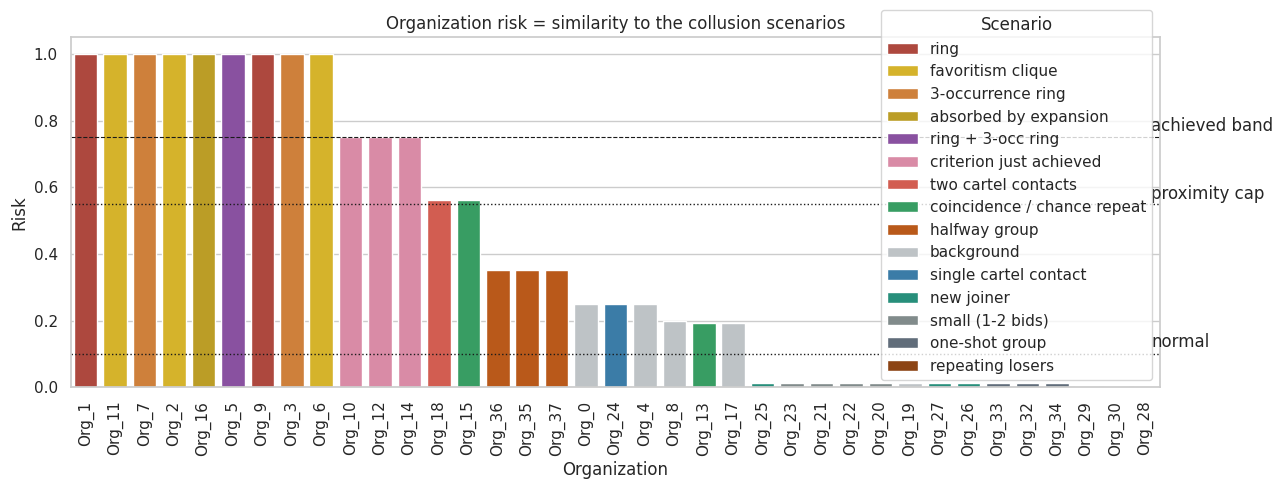

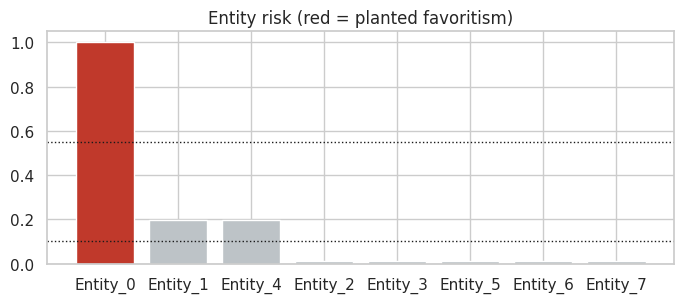

In [18]:
label = {o: "background" for o in org_A.index}
for o in ("Org_1", "Org_9"): label[o] = "ring"
label["Org_5"] = "ring + 3-occ ring"
for o in ("Org_3", "Org_7"): label[o] = "3-occurrence ring"
for o in ("Org_2", "Org_6", "Org_11"): label[o] = "favoritism clique"
label["Org_16"] = "absorbed by expansion"
for o in ("Org_10", "Org_12", "Org_14"): label[o] = "criterion just achieved"
for o in ("Org_32", "Org_33", "Org_34"): label[o] = "one-shot group"
for o in ("Org_28", "Org_29", "Org_30"): label[o] = "repeating losers"
for o in ("Org_35", "Org_36", "Org_37"): label[o] = "halfway group"
for o in ("Org_13", "Org_15"): label[o] = "coincidence / chance repeat"
for o in ("Org_20", "Org_21", "Org_22", "Org_23"): label[o] = "small (1-2 bids)"
for o in ("Org_25", "Org_26", "Org_27"): label[o] = "new joiner"
label["Org_24"] = "single cartel contact"
label["Org_18"] = "two cartel contacts"

pal = {"ring": "#c0392b", "ring + 3-occ ring": "#8e44ad",
       "3-occurrence ring": "#e67e22", "favoritism clique": "#f1c40f",
       "absorbed by expansion": "#d4ac0d", "criterion just achieved": "#e67ea2", "one-shot group": "#5d6d7e",
       "repeating losers": "#a04000", "halfway group": "#d35400",
       "coincidence / chance repeat": "#27ae60",
       "small (1-2 bids)": "#7f8c8d", "new joiner": "#16a085",
       "single cartel contact": "#2980b9",
       "two cartel contacts": "#e74c3c", "background": "#bdc3c7"}

plot = org_A[["overall"]].astype(float).reset_index()
plot.columns = ["Organization", "Risk"]
plot["Scenario"] = plot.Organization.map(label)
plt.figure(figsize=(13, 5))
sns.barplot(data=plot.sort_values("Risk", ascending=False),
            x="Organization", y="Risk", hue="Scenario", dodge=False, palette=pal)
plt.axhline(0.1, color="k", ls=":", lw=1); plt.axhline(0.55, color="k", ls=":", lw=1)
plt.axhline(0.75, color="k", ls="--", lw=0.8)
plt.text(36.2, 0.12, "normal"); plt.text(36.2, 0.565, "proximity cap")
plt.text(36.2, 0.77, "achieved band")
plt.xticks(rotation=90); plt.ylim(0, 1.05)
plt.title("Organization risk = similarity to the collusion scenarios")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7, 3.2))
ent = entity_A["overall"].astype(float).sort_values(ascending=False)
ax.bar(ent.index, ent.values,
       color=["#c0392b" if e == "Entity_0" else "#bdc3c7" for e in ent.index])
ax.axhline(0.1, color="k", ls=":", lw=1); ax.axhline(0.55, color="k", ls=":", lw=1)
ax.set_ylim(0, 1.05); ax.set_title("Entity risk (red = planted favoritism)")
plt.tight_layout(); plt.show()

## 11 — Adjusting the thresholds

Each threshold is a scenario definition, so changing one changes *what counts as the scenario*, never a fit to data: raise `REPEAT` to 4 only if your domain considers 3 joint tenders ordinary; move `SUCCESS`/`BID_GAP` only if the legal or economic definition of cartel success / cover pricing differs in your jurisdiction; the involvement head start `(contacts+1)/4` can be softened to `contacts/4` if a single appearance inside a cartel's tender should barely register. `PROXIMITY_CAP` (0.55) sets how visible a not-yet-achieved group may become — lower it if pre-criterion groups should stay quieter. Everything else — extraction, cliques, checks, similarity — stays as in the methodology. The Neo4j layer is pure storage following the CEDAR data model: swap `NEO4J_URI`/`NEO4J_AUTH` for your instance, and on the real knowledge graph only `read_from_neo4j`'s Cypher needs extending to the additional attributes.